# Multimodal Fusion for Skin Lesion Classification (PAD-UFES-20)

## 1. Project Overview

This notebook combines the two independent pipelines developed earlier:

- **Image model** - EfficientNetB0 (partial fine-tuning, class weights), the best model from the image notebook.
- **Tabular model** - Logistic Regression / Decision Tree on the clinical metadata, the two best models from the tabular notebook.

The question we answer: **does a multimodal fusion model give better results than either individual model?**

Four models are trained and compared on exactly the same patient-level split:

| Model | Description |
|---|---|
| Tabular only | Best classical model on clinical metadata (chosen by cross-validation) |
| Image only | EfficientNetB0 on images (same architecture as the image notebook) |
| Late fusion | Weighted average of the image and tabular probabilities |
| Intermediate fusion | One network: EfficientNetB0 image features + tabular features are concatenated and trained together |

### Evaluation protocol (identical for every model)

- Patient-level `StratifiedGroupKFold` (5 folds, seed 42) - the same folds as the image notebook.
- **Fold 0 = untouched test set.** Folds 1-4 = development data.
- 4-fold patient-level cross-validation on folds 1-4 is used for model selection and for the late-fusion weight.
- Final models are trained on all of folds 1-4 and evaluated **once** on fold 0.

### Alignment issues found in the two original notebooks and the fixes used in the fusion code

| # | Issue | Fix in this notebook |
|---|---|---|
| 1 | The two notebooks used **different data and different splits**: the image notebook used 2,271 images (after SHA-256 de-duplication) while the tabular notebook used 1,891 unique patient-lesion rows with its own fold assignment. Their test sets were therefore not the same, and a tabular test patient could be an image training patient. Fusion needs one row = one image + its clinical data. | One image-level DataFrame. The image notebook's split is reproduced exactly; clinical features come from the same row, so every model sees the same train / test patients. |
| 2 | The tabular notebook chose between baseline and tuned models, and between Decision Tree and Logistic Regression, by looking at **test-set** results (mild test leakage). | The tabular model is chosen by cross-validation on the development folds only. The test fold is touched once at the end. |
| 3 | Tabular used a single train/test split; the image notebook used validation + 4-fold CV. | Same CV + final-test protocol for all models. |
| 4 | Tabular notebook: `groups_train` is defined in cell 249 but used by the GridSearchCV cells above it (NameError when run top-to-bottom). | Patient groups come from the fold function; no hidden dependencies. |
| 5 | Image notebook hard-codes `assert SELECTED_MODEL == ...` and `assert FINAL_EPOCHS == 15`, which break if a rerun gives a different result. | Final epochs are computed from the CV runs (median best epoch). |
| 6 | Labels were strings in the tabular notebook and integers in the image notebook. | Integer labels in the fixed `CLASSES` order everywhere. |
| 7 | CV models relied on `EarlyStopping` to restore the best weights. | The best checkpoint is explicitly reloaded after each fold. |

**Preprocessing is kept exactly as in the original notebooks:** same 21 clinical features, `biopsed` excluded (target leakage), median imputation + standard scaling for age / diameters / Fitzpatrick, `"Missing"` category + one-hot encoding for the 17 categorical features, all fitted on the training data only. Images: RGB, 224 x 224 (`INTER_AREA`), same augmentation, class weights for imbalance.

In [ ]:
# ===== Google Colab setup (skipped automatically when run elsewhere) =====
import os

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DRIVE_DATASET = "/content/drive/MyDrive/Colab Notebooks/ML/PAD-UFES Dataset.zip"   # a .zip file OR a folder in your Drive
DRIVE_OUT     = "/content/drive/MyDrive/Colab Notebooks/ML/multimodal_artifacts"  # results are saved here

if IN_COLAB:
    drive.mount("/content/drive")
    if DRIVE_DATASET.lower().endswith(".zip"):
        import zipfile
        target = "/content/pad_ufes_data"
        if not os.path.isdir(target):
            print("Unzipping dataset (one-off, ~1-2 min)...")
            with zipfile.ZipFile(DRIVE_DATASET) as z:
                z.extractall(target)
        DRIVE_DATASET = target
    print("Colab ready. Dataset:", DRIVE_DATASET)
else:
    print("Not running on Colab: using local paths")

Mounted at /content/drive
Unzipping dataset (one-off, ~1-2 min)...
Colab ready. Dataset: /content/pad_ufes_data


## 2. Import Libraries

In [ ]:
import os, random, hashlib, gc
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0

# Sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef, roc_auc_score,
                             roc_curve, auc, classification_report, confusion_matrix)

In [ ]:
# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Visualisation settings
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

%matplotlib inline

## 3. Configuration

In [ ]:
# ---------------- configuration ----------------
CLASSES     = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]   # fixed label order (same as the image notebook)
NUM_CLASSES = len(CLASSES)
IMG_SIZE    = 224
BATCH_SIZE  = 32

# Patient-level data splitting (same as the image notebook)
N_FOLDS     = 5
TEST_FOLD   = 0                 # held-out test set (~20%)
DEV_FOLDS   = [1, 2, 3, 4]      # development folds used for cross-validation and final training

QUICK_TEST  = False             # True = tiny run (2 epochs) just to check that the code works
EPOCHS      = 2 if QUICK_TEST else 30     # maximum epochs per CV run (best epoch is selected on validation macro F1)
LEARNING_RATE = 1e-4            # fine-tuning learning rate used by the best image model

# ImageNet pretrained weights for transfer learning
PRETRAINED  = "imagenet"        # None = do not download pretrained weights

# Re-use results already saved on disk (useful if Colab disconnects).
# Set to False (or delete the results folder) to retrain everything.
USE_SAVED_RESULTS = False

# Dataset location. On Colab it comes from the setup cell above.
# Elsewhere: set the PAD_UFES_DIR environment variable, or type a path here.
MANUAL_DATASET_DIR = DRIVE_DATASET if IN_COLAB else None   # e.g. "D:/data/PAD-UFES Dataset"

# Output folders (the image cache is shared with the image notebook)
OUT_DIR = Path(DRIVE_OUT) if IN_COLAB else Path("skin_lesion_artifacts")
FUSION_DIR = OUT_DIR / ("fusion_quicktest" if QUICK_TEST else "fusion")
MODEL_DIR  = FUSION_DIR / "models"
RESULT_DIR = FUSION_DIR / "results"
for folder in [OUT_DIR, MODEL_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Environment checks
print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)
if not gpus:
    print("WARNING: No GPU detected. For Colab, select Runtime > Change runtime type > GPU.")

print("\nClasses:", CLASSES)
print("Image size:", IMG_SIZE, "| Batch size:", BATCH_SIZE, "| Max epochs:", EPOCHS)
print("Output directory:", FUSION_DIR.resolve())

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
Image size: 224 | Batch size: 32 | Max epochs: 30
Output directory: /content/drive/MyDrive/Colab Notebooks/ML/multimodal_artifacts/fusion


## 4. Load the Dataset

Images and metadata are loaded exactly as in the image notebook. The metadata file already contains the clinical features of every image, so the image and the tabular data are aligned by construction (one row = one image).

In [ ]:
# ============================================================
# 1. FIND THE DATASET DIRECTORY
# ============================================================

def find_dataset_dir():
    """Find the directory containing metadata.csv."""
    candidates = []

    if MANUAL_DATASET_DIR:
        manual = Path(MANUAL_DATASET_DIR).expanduser()
        candidates.append(manual)
        if manual.is_dir():
            candidates.extend(p.parent for p in manual.rglob("metadata.csv"))

    if os.environ.get("PAD_UFES_DIR"):
        candidates.append(Path(os.environ["PAD_UFES_DIR"]))

    here = Path.cwd().resolve()
    for base in [here, *list(here.parents)[:3]]:
        candidates.append(base)
        for folder_name in ["PAD-UFES Dataset", "PAD-UFES-20", "PAD-UFES", "pad-ufes-20"]:
            candidates.append(base / folder_name)
            candidates.append(base / "data" / folder_name)

    checked = set()
    for candidate in candidates:
        candidate = candidate.expanduser()
        if candidate in checked:
            continue
        checked.add(candidate)
        if (candidate / "metadata.csv").is_file():
            return candidate.resolve()

    raise FileNotFoundError("Dataset not found. Check MANUAL_DATASET_DIR or the PAD_UFES_DIR environment variable.")


def read_image(path):
    """Read an image with OpenCV and convert BGR to RGB."""
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Could not read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# ============================================================
# 2. LOCATE IMAGE FOLDERS AND FILES
# ============================================================

DATASET_DIR = find_dataset_dir()
print("Dataset directory:", DATASET_DIR)

IMAGE_DIRS = sorted(p for p in DATASET_DIR.glob("imgs_part_*") if p.is_dir())
if not IMAGE_DIRS:
    raise FileNotFoundError("No imgs_part_* directories found inside the dataset folder.")

files = [p for folder in IMAGE_DIRS for p in folder.rglob("*")
         if p.is_file() and p.suffix.lower() == ".png"]
if not files:
    raise FileNotFoundError("No PNG images found.")

# Filename-to-path lookup
paths = {}
for p in files:
    if p.name in paths:
        raise ValueError(f"Duplicate filename found in image folders: {p.name}")
    paths[p.name] = p

print("Image folders found:", len(IMAGE_DIRS))
print("Image files found:", len(files))

# ============================================================
# 3. LOAD AND VALIDATE METADATA
# ============================================================

meta = pd.read_csv(DATASET_DIR / "metadata.csv")

required_columns = ["img_id", "patient_id", "lesion_id", "diagnostic"]
missing_columns = [c for c in required_columns if c not in meta.columns]
if missing_columns:
    raise ValueError(f"Missing required metadata columns: {missing_columns}")

if meta["img_id"].isna().any():
    raise ValueError("Missing image IDs found in metadata.")
meta["img_id"] = meta["img_id"].astype(str).str.strip()
if meta["img_id"].duplicated().any():
    raise ValueError("Repeated img_id values found in metadata.csv.")

if not meta["diagnostic"].isin(CLASSES).all():
    unexpected = meta.loc[~meta["diagnostic"].isin(CLASSES), "diagnostic"].unique()
    raise ValueError(f"Unexpected or missing diagnosis labels: {unexpected}")

# Match metadata image IDs to image paths
meta["path"] = meta["img_id"].map(paths)
if meta["path"].isna().any():
    missing_images = meta.loc[meta["path"].isna(), "img_id"].tolist()
    raise FileNotFoundError(f"{len(missing_images)} metadata images were not found. Examples: {missing_images[:10]}")
meta["path"] = meta["path"].astype(str)

print("\nMetadata rows:", len(meta))
print("\nOriginal class distribution:")
print(meta["diagnostic"].value_counts().reindex(CLASSES))

Dataset directory: /content/pad_ufes_data/PAD-UFES Dataset
Image folders found: 3
Image files found: 2298

Metadata rows: 2298

Original class distribution:
diagnostic
ACK    730
BCC    845
MEL     52
NEV    244
SCC    192
SEK    235
Name: count, dtype: int64


In [ ]:
# ============================================================
# 5. IDENTIFY BYTE-IDENTICAL DUPLICATE IMAGES (same rule as the image notebook)
# ============================================================

def image_hash(path):
    """Calculate SHA-256 hash of an image file."""
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

meta["image_hash"] = meta["path"].map(image_hash)

drop_reasons = {}
for _, group in meta.groupby("image_hash"):
    if len(group) <= 1:
        continue

    if group["diagnostic"].nunique() == 1:
        # Same diagnosis: keep the first copy, remove the others
        for idx in group.index.tolist()[1:]:
            drop_reasons[idx] = "Identical image - same diagnosis"
    else:
        # Conflicting diagnoses: exclude every copy
        for idx in group.index.tolist():
            drop_reasons[idx] = "Identical image - conflicting diagnoses"

dropped_indices = sorted(drop_reasons.keys())

# Cleaned dataframe: ONE ROW = ONE IMAGE + its clinical metadata
df = meta.drop(index=dropped_indices).reset_index(drop=True)

print("Original images:", len(meta))
print("Removed images:", len(dropped_indices))
print("Remaining images:", len(df))
print("\nClass distribution after duplicate removal:")
print(df["diagnostic"].value_counts().reindex(CLASSES))

Original images: 2298
Removed images: 27
Remaining images: 2271

Class distribution after duplicate removal:
diagnostic
ACK    723
BCC    834
MEL     52
NEV    243
SCC    185
SEK    234
Name: count, dtype: int64


## 5. Patient-Level Data Splitting

The split is **identical to the image notebook** (same dataframe, same seed, same `StratifiedGroupKFold`), so the test set is the same one used for the image-only results. Every image of a patient is in exactly one fold, so no patient appears in both training and test data.

- **Test:** fold 0
- **Development (CV + final training):** folds 1, 2, 3, 4

In [ ]:
# Encode diagnostic labels as integers (fixed CLASSES order)
label_mapping = {c: i for i, c in enumerate(CLASSES)}
df["label"] = df["diagnostic"].map(label_mapping).astype(int)

# Assign each patient to exactly one fold
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (_, fold_idx) in enumerate(sgkf.split(X=df, y=df["label"], groups=df["patient_id"])):
    df.loc[fold_idx, "fold"] = fold

# Checks
assert (df["fold"] >= 0).all(), "Some images were not assigned to a fold!"
assert df.groupby("patient_id")["fold"].nunique().max() == 1, "A patient appears in more than one fold!"

# Development and test indices
dev_idx  = np.where(df["fold"].isin(DEV_FOLDS))[0]
test_idx = np.where(df["fold"] == TEST_FOLD)[0]

assert set(df.iloc[dev_idx]["patient_id"]).isdisjoint(set(df.iloc[test_idx]["patient_id"])), "Patient leakage!"

y = df["label"].to_numpy(dtype=np.int32)
y_test = y[test_idx]

print(f"Development: {len(dev_idx)} images | {df.iloc[dev_idx]['patient_id'].nunique()} patients")
print(f"Test:        {len(test_idx)} images | {df.iloc[test_idx]['patient_id'].nunique()} patients")

# Class counts per fold
fold_counts = pd.crosstab(df["fold"], df["diagnostic"])[CLASSES]
display(fold_counts)

# Save the split assignment
df[["img_id", "patient_id", "lesion_id", "diagnostic", "label", "fold"]].to_csv(RESULT_DIR / "splits.csv", index=False)

Development: 1803 images | 1096 patients
Test:        468 images | 275 patients


diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
fold,,,,,,
0,159,160,9,52,46,42
1,130,164,8,41,33,54
2,160,152,13,55,31,42
3,138,184,10,40,36,47
4,136,174,12,55,39,49


## 6. Image Preprocessing

All images are converted to RGB and resized to 224 x 224 (`INTER_AREA`). The resized images are cached (same cache file name as the image notebook, so an existing cache in your Drive is re-used).

In [ ]:
cache_version = "v2_rgb_resize_area"
cache_file = OUT_DIR / f"images_{IMG_SIZE}_{cache_version}.npz"

# Image IDs in the exact order of df
ids = np.array(df["img_id"].tolist(), dtype="U")

X_img = None

# Try loading an existing cache
if cache_file.exists():
    with np.load(cache_file, allow_pickle=False) as cache:
        if (np.array_equal(cache["ids"], ids)
                and str(cache["version"].item()) == cache_version
                and cache["images"].shape == (len(df), IMG_SIZE, IMG_SIZE, 3)):
            X_img = cache["images"]
            print("Loaded valid image cache.")
        else:
            print("Cache does not match current dataset/settings. Rebuilding image cache.")

# Build the cache if necessary
if X_img is None:
    X_img = np.zeros((len(df), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)

    for i, path in enumerate(df["path"]):
        img = read_image(path)
        X_img[i] = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

        if (i + 1) % 500 == 0 or (i + 1) == len(df):
            print(f"Resized {i + 1}/{len(df)} images")

    np.savez(cache_file, images=X_img, ids=ids, version=np.array(cache_version))
    print(f"Saved image cache: {cache_file}")

assert len(X_img) == len(y)
print("\nImages:", X_img.shape, X_img.dtype)
print("Labels:", y.shape, y.dtype)

Resized 500/2271 images
Resized 1000/2271 images
Resized 1500/2271 images
Resized 2000/2271 images
Resized 2271/2271 images
Saved image cache: /content/drive/MyDrive/Colab Notebooks/ML/multimodal_artifacts/images_224_v2_rgb_resize_area.npz

Images: (2271, 224, 224, 3) uint8
Labels: (2271,) int32


## 7. Tabular (Clinical) Preprocessing

Same features and same rules as the tabular notebook:

| Feature group | Features | Preprocessing |
|---|---|---|
| Numerical | age, diameter_1, diameter_2 | Median imputation + standardisation |
| Ordinal | fitspatrick | Median imputation + standardisation |
| Categorical (17) | gender, region, smoke, drink, itch, grew, ... | Missing -> `"Missing"` category, converted to text, one-hot encoding |

Excluded: `patient_id`, `lesion_id`, `img_id`, `diagnostic` (target) and **`biopsed`** (target leakage - a biopsy result is only known after diagnosis).

The imputers, encoder and scaler are **fitted on the training data of each run only** and then applied to the validation / test data.

Note: rows are image-level (one row per image carrying its lesion's clinical data), so a lesion with several images is repeated - exactly as the image model sees it. Patient-level splitting prevents any leakage from this.

In [ ]:
# ----- Feature groups (identical to the tabular notebook) -----
numerical_features = ["age", "diameter_1", "diameter_2"]
ordinal_features   = ["fitspatrick"]
categorical_features = [
    "smoke", "drink", "background_father", "background_mother", "pesticide",
    "gender", "skin_cancer_history", "cancer_history", "has_piped_water",
    "has_sewage_system", "region", "itch", "grew", "hurt", "changed",
    "bleed", "elevation"
]
# NOT used as features: patient_id, lesion_id, img_id, diagnostic (target), biopsed (leakage)

all_tabular = numerical_features + ordinal_features + categorical_features
missing_cols = [c for c in all_tabular if c not in df.columns]
assert not missing_cols, f"Columns missing from metadata: {missing_cols}"
print("Clinical features:", len(all_tabular), "(3 numerical + 1 ordinal + 17 categorical)")

# ----- Rule-free cleaning (uses no statistics, so it is safe to apply before splitting) -----
df_tab = df[all_tabular].copy()

for col in numerical_features + ordinal_features:
    df_tab[col] = pd.to_numeric(df_tab[col], errors="coerce")

# Missing categorical values -> "Missing"; everything converted to text
# (mixed True/False/text columns otherwise break the encoder)
df_tab[categorical_features] = df_tab[categorical_features].fillna("Missing").astype(str)


# ----- Statistics-based preprocessing (fitted on training data only) -----
def build_tab_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numerical_features + ordinal_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ])


def prepare_tabular(train_indices, *other_indices):
    """Fit the preprocessor on train_indices, then transform train + other sets."""
    preprocessor = build_tab_preprocessor()
    train_features = preprocessor.fit_transform(df_tab.iloc[train_indices]).astype("float32")
    others = [preprocessor.transform(df_tab.iloc[idx]).astype("float32") for idx in other_indices]
    return (train_features, *others)


# Quick check on the development data
demo_train, demo_test = prepare_tabular(dev_idx, test_idx)
print("Processed tabular features - development:", demo_train.shape, "| test:", demo_test.shape)
print("Missing values after preprocessing:", int(np.isnan(demo_train).sum() + np.isnan(demo_test).sum()))

Clinical features: 21 (3 numerical + 1 ordinal + 17 categorical)
Processed tabular features - development: (1803, 84) | test: (468, 84)
Missing values after preprocessing: 0


## 8. Helper Functions

Cross-validation folds, class weights, evaluation metrics, `tf.data` pipelines and training callbacks (same approach as the image notebook).

In [ ]:
# ----------------- folds and class weights -----------------

def get_fold_indices(val_fold):
    """Train on the other development folds, validate on val_fold (patient-level)."""
    folds = df["fold"].to_numpy()
    train_idx = np.where(np.isin(folds, [f for f in DEV_FOLDS if f != val_fold]))[0]
    val_idx = np.where(folds == val_fold)[0]

    assert set(df.iloc[train_idx]["patient_id"]).isdisjoint(set(df.iloc[val_idx]["patient_id"])), "Patient leakage detected!"
    return train_idx, val_idx


def get_class_weights(indices):
    """Balanced class weights computed from the given training indices only."""
    labels = y[indices]
    classes = np.unique(labels)
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=labels)
    return {int(c): float(w) for c, w in zip(classes, weights)}


def get_sample_weights(indices, class_weights):
    """One weight per training image (class weights -> sample weights)."""
    return np.array([class_weights[int(c)] for c in y[indices]], dtype="float32")


# ----------------- evaluation -----------------

def evaluate_predictions(y_true, probabilities):
    """Same metrics as the image notebook."""
    predictions = np.argmax(probabilities, axis=1)

    try:
        roc_auc = roc_auc_score(y_true, probabilities, multi_class="ovr",
                                average="macro", labels=np.arange(NUM_CLASSES))
    except ValueError:
        roc_auc = np.nan

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Macro Precision": precision_score(y_true, predictions, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, predictions, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, predictions, average="weighted", zero_division=0),
        "Macro ROC-AUC": roc_auc,
        "MCC": matthews_corrcoef(y_true, predictions)
    }


def predict_proba_all_classes(model, features):
    """predict_proba with one column for every class (even if a class is absent in training)."""
    probs = np.zeros((len(features), NUM_CLASSES))
    probs[:, model.classes_.astype(int)] = model.predict_proba(features)
    return probs


# ----------------- tf.data pipeline -----------------

def make_ds(indices, tabular=None, sample_weights=None, training=False):
    """
    Build a tf.data pipeline from the cached images.
    - image-only model : inputs = images
    - fusion model     : inputs = {"image": images, "tabular": features}
    """
    images = X_img[indices]
    inputs = images if tabular is None else {"image": images, "tabular": tabular}

    data = (inputs, y[indices]) if sample_weights is None else (inputs, y[indices], sample_weights)
    ds = tf.data.Dataset.from_tensor_slices(data)

    if training:
        ds = ds.shuffle(buffer_size=len(indices), seed=SEED, reshuffle_each_iteration=True)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# ----------------- callbacks -----------------

class ValidationMacroF1(keras.callbacks.Callback):
    """Compute validation macro F1 after every epoch (primary model-selection metric)."""
    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds

    def on_epoch_end(self, epoch, logs=None):
        y_true, y_pred = [], []
        for inputs, labels in self.val_ds:
            probs = self.model(inputs, training=False).numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(np.argmax(probs, axis=1))

        score = f1_score(y_true, y_pred, average="macro", zero_division=0)
        logs["val_macro_f1"] = score
        print(f" - val_macro_f1: {score:.4f}")


def get_callbacks(name, val_ds):
    return [
        ValidationMacroF1(val_ds),
        keras.callbacks.ModelCheckpoint(str(MODEL_DIR / f"{name}_best.weights.h5"),
                                        monitor="val_macro_f1", mode="max",
                                        save_best_only=True, save_weights_only=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5,
                                          patience=5, min_lr=1e-6, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=10,
                                      restore_best_weights=True, verbose=1)
    ]

## 9. Model Architectures

**Image branch (shared by the image-only and fusion models)** - identical to the best image model from the image notebook: augmentation -> EfficientNetB0 (blocks 6, 7 and top unfrozen, Batch Normalisation frozen) -> global average pooling -> Dense(256) -> Dropout(0.3).

**Tabular branch (fusion model only)** - a small MLP on the preprocessed clinical features: Dense(64) -> Dropout(0.3) -> Dense(32), following the MLP size used in the tabular notebook.

**Intermediate (feature-level) fusion** - the 256 image features and the 32 tabular features are concatenated -> Dense(128) -> Dropout(0.3) -> softmax. Both branches are trained together.

In [ ]:
def build_augmentation():
    """Same augmentation as the image notebook (only active during training)."""
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.10, fill_mode="reflect"),
        layers.RandomZoom(0.10, fill_mode="reflect"),
        layers.RandomContrast(0.10),
    ], name="augmentation")


def build_efficientnet_backbone():
    """EfficientNetB0 with partial fine-tuning: block6, block7 and top unfrozen, BatchNorm frozen."""
    base = EfficientNetB0(include_top=False, weights=PRETRAINED,
                          input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = True

    for layer in base.layers:
        layer.trainable = (layer.name.startswith("block6")
                           or layer.name.startswith("block7")
                           or layer.name.startswith("top"))
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    return base


def image_branch(image_input):
    """augmentation -> EfficientNetB0 -> GAP -> Dense(256) -> Dropout(0.3)"""
    x = build_augmentation()(image_input)
    x = build_efficientnet_backbone()(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    return x


def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    trainable = sum(np.prod(w.shape) for w in model.trainable_weights)
    print(f"{model.name}: trainable parameters = {trainable:,}")
    return model


def create_image_model(lr=LEARNING_RATE):
    """Image-only model (best model of the image notebook)."""
    image_input = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = image_branch(image_input)
    output = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(image_input, output, name="Image_EfficientNetB0")
    return compile_model(model, lr)


def create_fusion_model(n_tabular_features, lr=LEARNING_RATE):
    """Intermediate fusion: image features + tabular features -> classifier."""
    image_input = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    tabular_input = keras.Input((n_tabular_features,), name="tabular")

    # Branch 1: image
    image_features = image_branch(image_input)

    # Branch 2: tabular
    t = layers.Dense(64, activation="relu")(tabular_input)
    t = layers.Dropout(0.3)(t)
    tabular_features = layers.Dense(32, activation="relu")(t)

    # Fusion head
    x = layers.Concatenate()([image_features, tabular_features])
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model({"image": image_input, "tabular": tabular_input}, output,
                        name="Fusion_EfficientNetB0_Tabular")
    return compile_model(model, lr)


# Quick architecture check
_m = create_fusion_model(demo_train.shape[1])
_m.summary(line_length=100)
del _m
keras.backend.clear_session()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Fusion_EfficientNetB0_Tabular: trainable parameters = 3,503,106


Model: "Fusion_EfficientNetB0_Tabular"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)     │              0 │ image[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)      │      4,049,571 │ augmentation[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ tabular (InputLayer)        │ (None, 84)              │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ global_average_pooling2d    │ (None, 1280)            │              0 │ efficientnetb0[0][0]    │
│ (GlobalAveragePooling2D)    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense_1 (Dense)             │ (None, 64)              │          5,440 │ tabular[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense (Dense)               │ (None, 256)             │        327,936 │ global_average_pooling… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_1 (Dropout)         │ (None, 64)              │              0 │ dense_1[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout (Dropout)           │ (None, 256)             │              0 │ dense[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense_2 (Dense)             │ (None, 32)              │          2,080 │ dropout_1[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ concatenate (Concatenate)   │ (None, 288)             │              0 │ dropout[0][0],          │
│                             │                         │                │ dense_2[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense_3 (Dense)             │ (None, 128)             │         36,992 │ concatenate[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_2 (Dropout)         │ (None, 128)             │              0 │ dense_3[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense_4 (Dense)             │ (None, 6)               │            774 │ dropout_2[0][0]         │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 4,422,793 (16.87 MB)

 Trainable params: 3,503,106 (13.36 MB)

 Non-trainable params: 919,687 (3.51 MB)

## 10. Cross-Validation on the Development Folds (folds 1-4)

Each model is trained 4 times; every time one development fold is the validation set and the other three are used for training. Class weights and tabular preprocessing are recomputed from the training folds only. The epoch with the best validation macro F1 is used for the validation predictions, and the median best epoch becomes the number of epochs for the final model.

### 10.1 Tabular-only models

Both tabular models retained in the tabular notebook are evaluated (Logistic Regression: best accuracy / weighted F1; Decision Tree: best macro F1). The better one **by cross-validation** is used as the "Tabular only" model and in late fusion.

In [ ]:
# Tabular models retained from the tabular notebook (same settings)
tabular_models = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree":       lambda: DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=SEED),
}

fold_val_idx = {}                              # validation indices of every CV fold
tab_cv_probs = {name: {} for name in tabular_models}
tab_cv_rows = []

for val_fold in DEV_FOLDS:
    train_idx, val_idx = get_fold_indices(val_fold)
    fold_val_idx[val_fold] = val_idx

    # Fit preprocessing on the training folds only
    T_train, T_val = prepare_tabular(train_idx, val_idx)

    for name, make_model in tabular_models.items():
        model = make_model().fit(T_train, y[train_idx])
        probs = predict_proba_all_classes(model, T_val)

        tab_cv_probs[name][val_fold] = probs
        tab_cv_rows.append({"Model": name, "Fold": val_fold, **evaluate_predictions(y[val_idx], probs)})

tab_cv_df = pd.DataFrame(tab_cv_rows)
display(tab_cv_df.groupby("Model")[["Accuracy", "Macro F1", "Weighted F1", "Macro ROC-AUC"]].agg(["mean", "std"]).round(4))

# Select the best tabular model by mean CV macro F1 (the test set is NOT used)
best_tab_name = tab_cv_df.groupby("Model")["Macro F1"].mean().idxmax()
print("Selected tabular model (by CV macro F1):", best_tab_name)

Accuracy         Macro F1         Weighted F1          \
                        mean     std     mean     std        mean     std   
Model                                                                       
Decision Tree         0.6887  0.0245   0.4721  0.0211      0.6533  0.0178   
Logistic Regression   0.7314  0.0232   0.5931  0.0338      0.7171  0.0225   

                    Macro ROC-AUC          
                             mean     std  
Model                                      
Decision Tree              0.8555  0.0096  
Logistic Regression        0.9136  0.0119

Selected tabular model (by CV macro F1): Logistic Regression


### 10.2 Image-only model and intermediate fusion model

The same function trains both deep models with the same folds, class weights, learning rate, callbacks and seeds. The only difference is that the fusion model also receives the clinical features.

In [ ]:
def run_cv(model_name, use_tabular):
    """4-fold patient-level CV for a deep model. Returns validation probabilities per fold,
    the best epoch of every fold and a table of fold metrics."""
    fold_probs, best_epochs, rows = {}, [], []

    for val_fold in DEV_FOLDS:
        run_name = f"cv_{model_name}_fold_{val_fold}"
        saved_file = RESULT_DIR / f"{run_name}_val_probs.npz"
        train_idx, val_idx = get_fold_indices(val_fold)

        if USE_SAVED_RESULTS and saved_file.exists():
            saved = np.load(saved_file)
            probs, best_epoch = saved["probs"], int(saved["best_epoch"])
            print(f"{run_name}: loaded saved results")

        else:
            print(f"\n{'=' * 60}\n{model_name} | validation fold {val_fold}\n{'=' * 60}")
            keras.backend.clear_session()
            tf.keras.utils.set_random_seed(SEED + val_fold)

            class_weights = get_class_weights(train_idx)
            sample_weights = get_sample_weights(train_idx, class_weights)

            if use_tabular:
                T_train, T_val = prepare_tabular(train_idx, val_idx)   # fitted on training folds only
                model = create_fusion_model(T_train.shape[1])
            else:
                T_train, T_val = None, None
                model = create_image_model()

            train_ds = make_ds(train_idx, T_train, sample_weights, training=True)
            val_ds = make_ds(val_idx, T_val)

            history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                                callbacks=get_callbacks(run_name, val_ds), shuffle=False, verbose=2)

            # Reload the checkpoint with the best validation macro F1
            best_epoch = int(np.argmax(history.history["val_macro_f1"]) + 1)
            model.load_weights(MODEL_DIR / f"{run_name}_best.weights.h5")
            probs = model.predict(val_ds, verbose=0)

            pd.DataFrame(history.history).to_csv(RESULT_DIR / f"{run_name}_history.csv", index=False)
            np.savez(saved_file, probs=probs, best_epoch=best_epoch)

            del model, train_ds, val_ds
            keras.backend.clear_session()
            gc.collect()

        fold_probs[val_fold] = probs
        best_epochs.append(best_epoch)
        metrics = evaluate_predictions(y[val_idx], probs)
        rows.append({"Fold": val_fold, "Best Epoch": best_epoch, **metrics})
        print(f"Fold {val_fold}: best epoch {best_epoch} | macro F1 {metrics['Macro F1']:.4f}")

    return fold_probs, best_epochs, pd.DataFrame(rows)

In [ ]:
# ----- Image-only CV -----
img_cv_probs, img_best_epochs, img_cv_df = run_cv("image_only", use_tabular=False)
display(img_cv_df.round(4))


image_only | validation fold 1
Image_EfficientNetB0: trainable parameters = 3,459,362
Epoch 1/30
 - val_macro_f1: 0.3174
43/43 - 36s - 846ms/step - accuracy: 0.3190 - loss: 1.6707 - val_accuracy: 0.4000 - val_loss: 1.4696 - val_macro_f1: 0.3174 - learning_rate: 1.0000e-04
Epoch 2/30
 - val_macro_f1: 0.3507
43/43 - 12s - 286ms/step - accuracy: 0.4749 - loss: 1.2000 - val_accuracy: 0.5000 - val_loss: 1.2246 - val_macro_f1: 0.3507 - learning_rate: 1.0000e-04
Epoch 3/30
 - val_macro_f1: 0.4879
43/43 - 17s - 398ms/step - accuracy: 0.5790 - loss: 0.9701 - val_accuracy: 0.5698 - val_loss: 1.1063 - val_macro_f1: 0.4879 - learning_rate: 1.0000e-04
Epoch 4/30
 - val_macro_f1: 0.5119
43/43 - 12s - 268ms/step - accuracy: 0.6315 - loss: 0.8175 - val_accuracy: 0.6512 - val_loss: 0.9616 - val_macro_f1: 0.5119 - learning_rate: 1.0000e-04
Epoch 5/30
 - val_macro_f1: 0.4710
43/43 - 15s - 350ms/step - accuracy: 0.6744 - loss: 0.7446 - val_accuracy: 0.6326 - val_loss: 0.9701 - val_macro_f1: 0.4710 - lear

,Fold,Best Epoch,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC,MCC
0,1,12,0.6442,0.5942,0.5761,0.5942,0.5749,0.6639,0.8798,0.5356
1,2,11,0.7020,0.6561,0.6731,0.6561,0.6515,0.7090,0.8957,0.6058
2,3,15,0.7055,0.6638,0.6259,0.6638,0.6401,0.6969,0.9021,0.5893
3,4,12,0.6430,0.6361,0.6763,0.6361,0.6403,0.6613,0.9113,0.5433


In [ ]:
# ----- Intermediate fusion CV -----
fus_cv_probs, fus_best_epochs, fus_cv_df = run_cv("intermediate_fusion", use_tabular=True)
display(fus_cv_df.round(4))


intermediate_fusion | validation fold 1
Fusion_EfficientNetB0_Tabular: trainable parameters = 3,503,042
Epoch 1/30
 - val_macro_f1: 0.3245
43/43 - 28s - 649ms/step - accuracy: 0.3103 - loss: 1.7206 - val_accuracy: 0.4651 - val_loss: 1.5084 - val_macro_f1: 0.3245 - learning_rate: 1.0000e-04
Epoch 2/30
 - val_macro_f1: 0.3539
43/43 - 10s - 244ms/step - accuracy: 0.4479 - loss: 1.3901 - val_accuracy: 0.5047 - val_loss: 1.2940 - val_macro_f1: 0.3539 - learning_rate: 1.0000e-04
Epoch 3/30
 - val_macro_f1: 0.4226
43/43 - 10s - 239ms/step - accuracy: 0.5135 - loss: 1.1851 - val_accuracy: 0.5535 - val_loss: 1.1391 - val_macro_f1: 0.4226 - learning_rate: 1.0000e-04
Epoch 4/30
 - val_macro_f1: 0.4906
43/43 - 11s - 253ms/step - accuracy: 0.5528 - loss: 1.0203 - val_accuracy: 0.6395 - val_loss: 0.9964 - val_macro_f1: 0.4906 - learning_rate: 1.0000e-04
Epoch 5/30
 - val_macro_f1: 0.4440
43/43 - 10s - 242ms/step - accuracy: 0.5899 - loss: 0.9177 - val_accuracy: 0.6209 - val_loss: 1.0026 - val_macro

,Fold,Best Epoch,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC,MCC
0,1,23,0.7163,0.6095,0.5917,0.6095,0.5976,0.7175,0.8951,0.6128
1,2,10,0.7219,0.6612,0.6810,0.6612,0.6537,0.7336,0.9073,0.6326
2,3,20,0.7582,0.6757,0.6998,0.6757,0.6853,0.7539,0.9205,0.6622
3,4,10,0.6667,0.6733,0.6757,0.6733,0.6628,0.6827,0.9226,0.5758


### 10.3 Late fusion

Late fusion needs no extra training: the probabilities of the image model and the tabular model are combined with a weighted average

$$p_{fusion} = w \cdot p_{image} + (1 - w) \cdot p_{tabular}$$

The image weight `w` is selected on the pooled cross-validation (out-of-fold) predictions of the development folds - the test set is not used.

Best image weight w = 0.4  (tabular weight = 0.6)
CV macro F1: image only (w=1.0) = 0.6304 | tabular only (w=0.0) = 0.5957 | late fusion = 0.6964


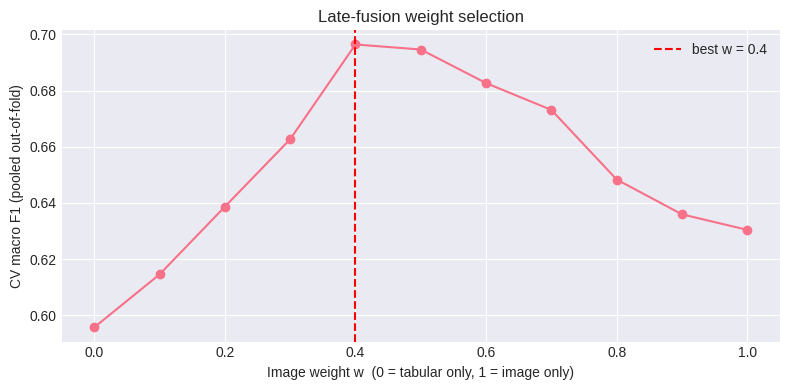

In [ ]:
# Pool the out-of-fold predictions of the 4 CV folds
y_oof = np.concatenate([y[fold_val_idx[f]] for f in DEV_FOLDS])
P_img = np.concatenate([img_cv_probs[f] for f in DEV_FOLDS])
P_tab = np.concatenate([tab_cv_probs[best_tab_name][f] for f in DEV_FOLDS])

# Search the image weight w
weight_grid = np.round(np.arange(0.0, 1.01, 0.1), 1)
oof_scores = [f1_score(y_oof, (w * P_img + (1 - w) * P_tab).argmax(1), average="macro", zero_division=0)
              for w in weight_grid]

best_w = float(weight_grid[int(np.argmax(oof_scores))])
print(f"Best image weight w = {best_w}  (tabular weight = {1 - best_w:.1f})")
print(f"CV macro F1: image only (w=1.0) = {oof_scores[-1]:.4f} | tabular only (w=0.0) = {oof_scores[0]:.4f} | late fusion = {max(oof_scores):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(weight_grid, oof_scores, "o-")
plt.axvline(best_w, color="red", linestyle="--", label=f"best w = {best_w}")
plt.xlabel("Image weight w  (0 = tabular only, 1 = image only)")
plt.ylabel("CV macro F1 (pooled out-of-fold)")
plt.title("Late-fusion weight selection")
plt.legend()
plt.tight_layout()
plt.show()

# Late-fusion metrics per fold
late_cv_probs = {f: best_w * img_cv_probs[f] + (1 - best_w) * tab_cv_probs[best_tab_name][f] for f in DEV_FOLDS}
late_cv_df = pd.DataFrame([{"Fold": f, **evaluate_predictions(y[fold_val_idx[f]], late_cv_probs[f])} for f in DEV_FOLDS])

### 10.4 Cross-validation comparison

Cross-validation results (mean +/- std over 4 folds). Tabular model used: Logistic Regression


,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Macro ROC-AUC,MCC
Model,,,,,,
Tabular only,0.731 +/- 0.023,0.588 +/- 0.047,0.593 +/- 0.034,0.717 +/- 0.023,0.914 +/- 0.012,0.627 +/- 0.030
Image only,0.674 +/- 0.035,0.638 +/- 0.031,0.627 +/- 0.035,0.683 +/- 0.024,0.897 +/- 0.013,0.568 +/- 0.034
Late fusion,0.790 +/- 0.014,0.684 +/- 0.031,0.694 +/- 0.021,0.778 +/- 0.009,0.936 +/- 0.009,0.711 +/- 0.017
Intermediate fusion,0.716 +/- 0.038,0.655 +/- 0.031,0.650 +/- 0.037,0.722 +/- 0.030,0.911 +/- 0.013,0.621 +/- 0.036


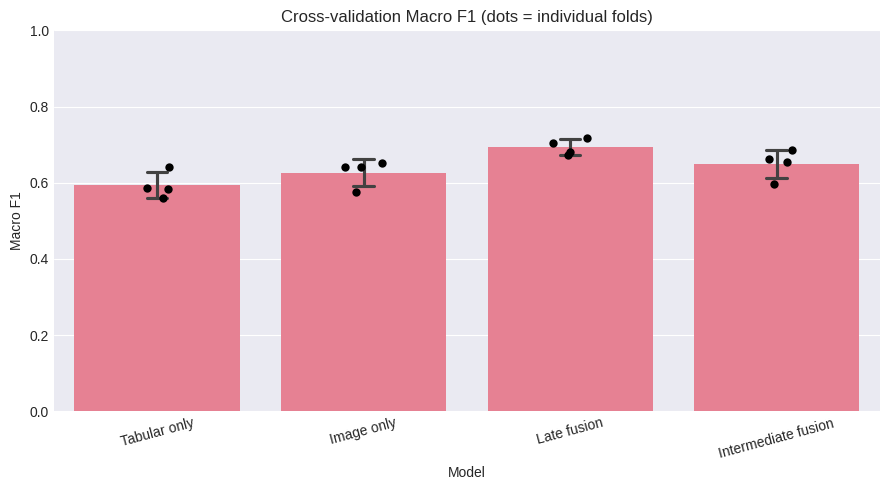

In [ ]:
MODEL_ORDER = ["Tabular only", "Image only", "Late fusion", "Intermediate fusion"]
metric_cols = ["Accuracy", "Balanced Accuracy", "Macro F1", "Weighted F1", "Macro ROC-AUC", "MCC"]

cv_all = pd.concat([
    tab_cv_df[tab_cv_df["Model"] == best_tab_name].assign(Model="Tabular only"),
    img_cv_df.assign(Model="Image only"),
    late_cv_df.assign(Model="Late fusion"),
    fus_cv_df.assign(Model="Intermediate fusion"),
], ignore_index=True)

cv_all.to_csv(RESULT_DIR / "cv_fold_results.csv", index=False)

# mean +/- std over the 4 folds
cv_table = pd.DataFrame({
    m: cv_all.groupby("Model")[m].apply(lambda s: f"{s.mean():.3f} +/- {s.std():.3f}")
    for m in metric_cols
}).reindex(MODEL_ORDER)

print(f"Cross-validation results (mean +/- std over {len(DEV_FOLDS)} folds). Tabular model used: {best_tab_name}")
display(cv_table)

plt.figure(figsize=(9, 5))
sns.barplot(data=cv_all, x="Model", y="Macro F1", order=MODEL_ORDER, errorbar="sd", capsize=0.1)
sns.stripplot(data=cv_all, x="Model", y="Macro F1", order=MODEL_ORDER, color="black", size=6)
plt.title("Cross-validation Macro F1 (dots = individual folds)")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 11. Final Training on All Development Folds

Each model is retrained on all of folds 1-4 and predicts the test fold (fold 0) **once**.

- Number of epochs for the deep models = median best epoch from the CV runs.
- Class weights and tabular preprocessing are recomputed from all development folds.

In [ ]:
FINAL_EPOCHS_IMG = max(1, int(np.median(img_best_epochs)))
FINAL_EPOCHS_FUS = max(1, int(np.median(fus_best_epochs)))
print("Final epochs - image only:", FINAL_EPOCHS_IMG, "| intermediate fusion:", FINAL_EPOCHS_FUS)

dev_class_weights = get_class_weights(dev_idx)
dev_sample_weights = get_sample_weights(dev_idx, dev_class_weights)
print("Class weights (development folds):", {CLASSES[k]: round(v, 2) for k, v in dev_class_weights.items()})


def train_final_deep_model(model_name, use_tabular, epochs):
    """Train on all development folds and return test-fold probabilities."""
    saved_file = RESULT_DIR / f"final_{model_name}_test_probs.npz"
    if USE_SAVED_RESULTS and saved_file.exists():
        print(f"{model_name}: loaded saved test predictions")
        return np.load(saved_file)["probs"]

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    if use_tabular:
        T_dev, T_test = prepare_tabular(dev_idx, test_idx)       # fitted on development folds only
        model = create_fusion_model(T_dev.shape[1])
    else:
        T_dev, T_test = None, None
        model = create_image_model()

    train_ds = make_ds(dev_idx, T_dev, dev_sample_weights, training=True)
    test_ds = make_ds(test_idx, T_test)

    history = model.fit(train_ds, epochs=epochs, shuffle=False, verbose=2)
    model.save_weights(MODEL_DIR / f"final_{model_name}.weights.h5")
    pd.DataFrame(history.history).to_csv(RESULT_DIR / f"final_{model_name}_history.csv", index=False)

    probs = model.predict(test_ds, verbose=0)
    np.savez(saved_file, probs=probs)

    del model, train_ds, test_ds
    keras.backend.clear_session()
    gc.collect()
    return probs

Final epochs - image only: 12 | intermediate fusion: 15
Class weights (development folds): {'ACK': 0.53, 'BCC': 0.45, 'MEL': 6.99, 'NEV': 1.57, 'SCC': 2.16, 'SEK': 1.57}


In [ ]:
# ----- Tabular only (selected model, fitted on all development folds) -----
T_dev, T_test = prepare_tabular(dev_idx, test_idx)
final_tab_model = tabular_models[best_tab_name]().fit(T_dev, y[dev_idx])
test_probs_tab = predict_proba_all_classes(final_tab_model, T_test)
print("Tabular model trained:", best_tab_name)

Tabular model trained: Logistic Regression


In [ ]:
# ----- Image only -----
test_probs_img = train_final_deep_model("image_only", use_tabular=False, epochs=FINAL_EPOCHS_IMG)

Image_EfficientNetB0: trainable parameters = 3,459,362
Epoch 1/12
57/57 - 19s - 339ms/step - accuracy: 0.3871 - loss: 1.6083
Epoch 2/12
57/57 - 5s - 91ms/step - accuracy: 0.5291 - loss: 1.1488
Epoch 3/12
57/57 - 5s - 90ms/step - accuracy: 0.5907 - loss: 0.9346
Epoch 4/12
57/57 - 5s - 95ms/step - accuracy: 0.6622 - loss: 0.8080
Epoch 5/12
57/57 - 5s - 90ms/step - accuracy: 0.6761 - loss: 0.7092
Epoch 6/12
57/57 - 5s - 92ms/step - accuracy: 0.7149 - loss: 0.6513
Epoch 7/12
57/57 - 10s - 179ms/step - accuracy: 0.7393 - loss: 0.5896
Epoch 8/12
57/57 - 5s - 94ms/step - accuracy: 0.7610 - loss: 0.4827
Epoch 9/12
57/57 - 10s - 176ms/step - accuracy: 0.7826 - loss: 0.4379
Epoch 10/12
57/57 - 5s - 94ms/step - accuracy: 0.7970 - loss: 0.4154
Epoch 11/12
57/57 - 5s - 89ms/step - accuracy: 0.8148 - loss: 0.3863
Epoch 12/12
57/57 - 5s - 91ms/step - accuracy: 0.8197 - loss: 0.3506


In [ ]:
# ----- Intermediate fusion -----
test_probs_fus = train_final_deep_model("intermediate_fusion", use_tabular=True, epochs=FINAL_EPOCHS_FUS)

Fusion_EfficientNetB0_Tabular: trainable parameters = 3,503,106
Epoch 1/15
57/57 - 20s - 348ms/step - accuracy: 0.2673 - loss: 1.7299
Epoch 2/15
57/57 - 5s - 95ms/step - accuracy: 0.4326 - loss: 1.4027
Epoch 3/15
57/57 - 5s - 92ms/step - accuracy: 0.5025 - loss: 1.1706
Epoch 4/15
57/57 - 5s - 92ms/step - accuracy: 0.5446 - loss: 1.0256
Epoch 5/15
57/57 - 5s - 96ms/step - accuracy: 0.5890 - loss: 0.9345
Epoch 6/15
57/57 - 5s - 92ms/step - accuracy: 0.6528 - loss: 0.7884
Epoch 7/15
57/57 - 5s - 94ms/step - accuracy: 0.6705 - loss: 0.7475
Epoch 8/15
57/57 - 5s - 93ms/step - accuracy: 0.6689 - loss: 0.6643
Epoch 9/15
57/57 - 5s - 91ms/step - accuracy: 0.7027 - loss: 0.6084
Epoch 10/15
57/57 - 5s - 95ms/step - accuracy: 0.7465 - loss: 0.5603
Epoch 11/15
57/57 - 5s - 91ms/step - accuracy: 0.7554 - loss: 0.4905
Epoch 12/15
57/57 - 5s - 91ms/step - accuracy: 0.7554 - loss: 0.4904
Epoch 13/15
57/57 - 5s - 94ms/step - accuracy: 0.7787 - loss: 0.4687
Epoch 14/15
57/57 - 5s - 90ms/step - accuracy:

In [ ]:
# ----- Late fusion (weight chosen by cross-validation) -----
test_probs_late = best_w * test_probs_img + (1 - best_w) * test_probs_tab

test_probs = {
    "Tabular only": test_probs_tab,
    "Image only": test_probs_img,
    "Late fusion": test_probs_late,
    "Intermediate fusion": test_probs_fus,
}

for name, probs in test_probs.items():
    assert probs.shape == (len(test_idx), NUM_CLASSES), f"Unexpected prediction shape for {name}"
print("All test predictions ready:", {k: v.shape for k, v in test_probs.items()})

All test predictions ready: {'Tabular only': (468, 6), 'Image only': (468, 6), 'Late fusion': (468, 6), 'Intermediate fusion': (468, 6)}


## 12. Final Test Evaluation

All four models are evaluated on the same held-out test fold (fold 0).

In [ ]:
test_results = pd.DataFrame({name: evaluate_predictions(y_test, probs)
                             for name, probs in test_probs.items()}).T.reindex(MODEL_ORDER)

test_results.to_csv(RESULT_DIR / "final_test_metrics.csv")

print(f"FINAL TEST RESULTS - fold {TEST_FOLD} ({len(test_idx)} images, {df.iloc[test_idx]['patient_id'].nunique()} patients)")
display(test_results.style.format("{:.4f}").highlight_max(axis=0, color="lightgreen"))

FINAL TEST RESULTS - fold 0 (468 images, 275 patients)


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC,MCC
Tabular only,0.7521,0.6493,0.7002,0.6493,0.6614,0.7396,0.9190,0.6607
Image only,0.7222,0.6476,0.6720,0.6476,0.6465,0.7089,0.9067,0.6177
Late fusion,0.8034,0.7258,0.8043,0.7258,0.7486,0.7893,0.9448,0.7328
Intermediate fusion,0.6667,0.6558,0.6628,0.6558,0.6505,0.6882,0.9159,0.5699


In [ ]:
# Classification reports
for name, probs in test_probs.items():
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, probs.argmax(1), labels=np.arange(NUM_CLASSES),
                                target_names=CLASSES, zero_division=0))


Tabular only
              precision    recall  f1-score   support

         ACK       0.82      0.80      0.81       159
         BCC       0.72      0.89      0.80       160
         MEL       0.56      0.56      0.56         9
         NEV       0.75      0.75      0.75        52
         SCC       0.60      0.26      0.36        46
         SEK       0.75      0.64      0.69        42

    accuracy                           0.75       468
   macro avg       0.70      0.65      0.66       468
weighted avg       0.75      0.75      0.74       468


Image only
              precision    recall  f1-score   support

         ACK       0.75      0.82      0.79       159
         BCC       0.74      0.81      0.77       160
         MEL       0.64      0.78      0.70         9
         NEV       0.71      0.79      0.75        52
         SCC       0.44      0.26      0.33        46
         SEK       0.75      0.43      0.55        42

    accuracy                           0.72       4

Per-class F1-score (test)


,Tabular only,Image only,Late fusion,Intermediate fusion,Test support
ACK,0.812,0.787,0.862,0.791,159
BCC,0.796,0.772,0.837,0.678,160
MEL,0.556,0.700,0.875,0.706,9
NEV,0.750,0.745,0.857,0.774,52
SCC,0.364,0.329,0.358,0.288,46
SEK,0.692,0.545,0.703,0.667,42


Per-class recall (test)


,Tabular only,Image only,Late fusion,Intermediate fusion
ACK,0.799,0.824,0.843,0.748
BCC,0.888,0.806,0.931,0.606
MEL,0.556,0.778,0.778,0.667
NEV,0.750,0.788,0.923,0.788
SCC,0.261,0.261,0.261,0.435
SEK,0.643,0.429,0.619,0.690


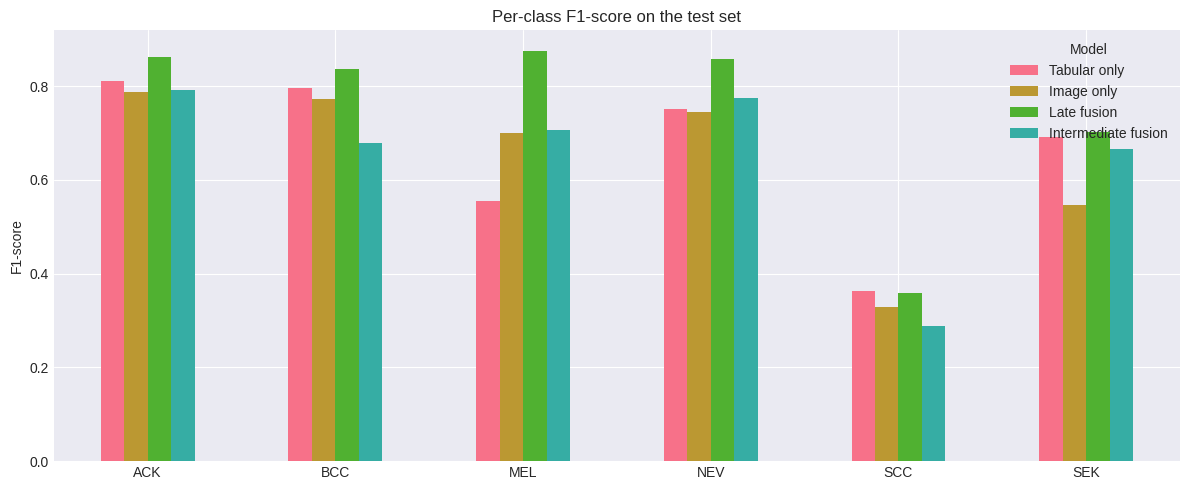

In [ ]:
# Per-class F1 and recall
per_class_f1 = pd.DataFrame({name: f1_score(y_test, p.argmax(1), average=None,
                                            labels=np.arange(NUM_CLASSES), zero_division=0)
                             for name, p in test_probs.items()}, index=CLASSES)[MODEL_ORDER]

per_class_recall = pd.DataFrame({name: recall_score(y_test, p.argmax(1), average=None,
                                                    labels=np.arange(NUM_CLASSES), zero_division=0)
                                 for name, p in test_probs.items()}, index=CLASSES)[MODEL_ORDER]

per_class_f1["Test support"] = np.bincount(y_test, minlength=NUM_CLASSES)

print("Per-class F1-score (test)")
display(per_class_f1.round(3))
print("Per-class recall (test)")
display(per_class_recall.round(3))

per_class_f1.drop(columns="Test support").plot(kind="bar", figsize=(12, 5))
plt.title("Per-class F1-score on the test set")
plt.ylabel("F1-score")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

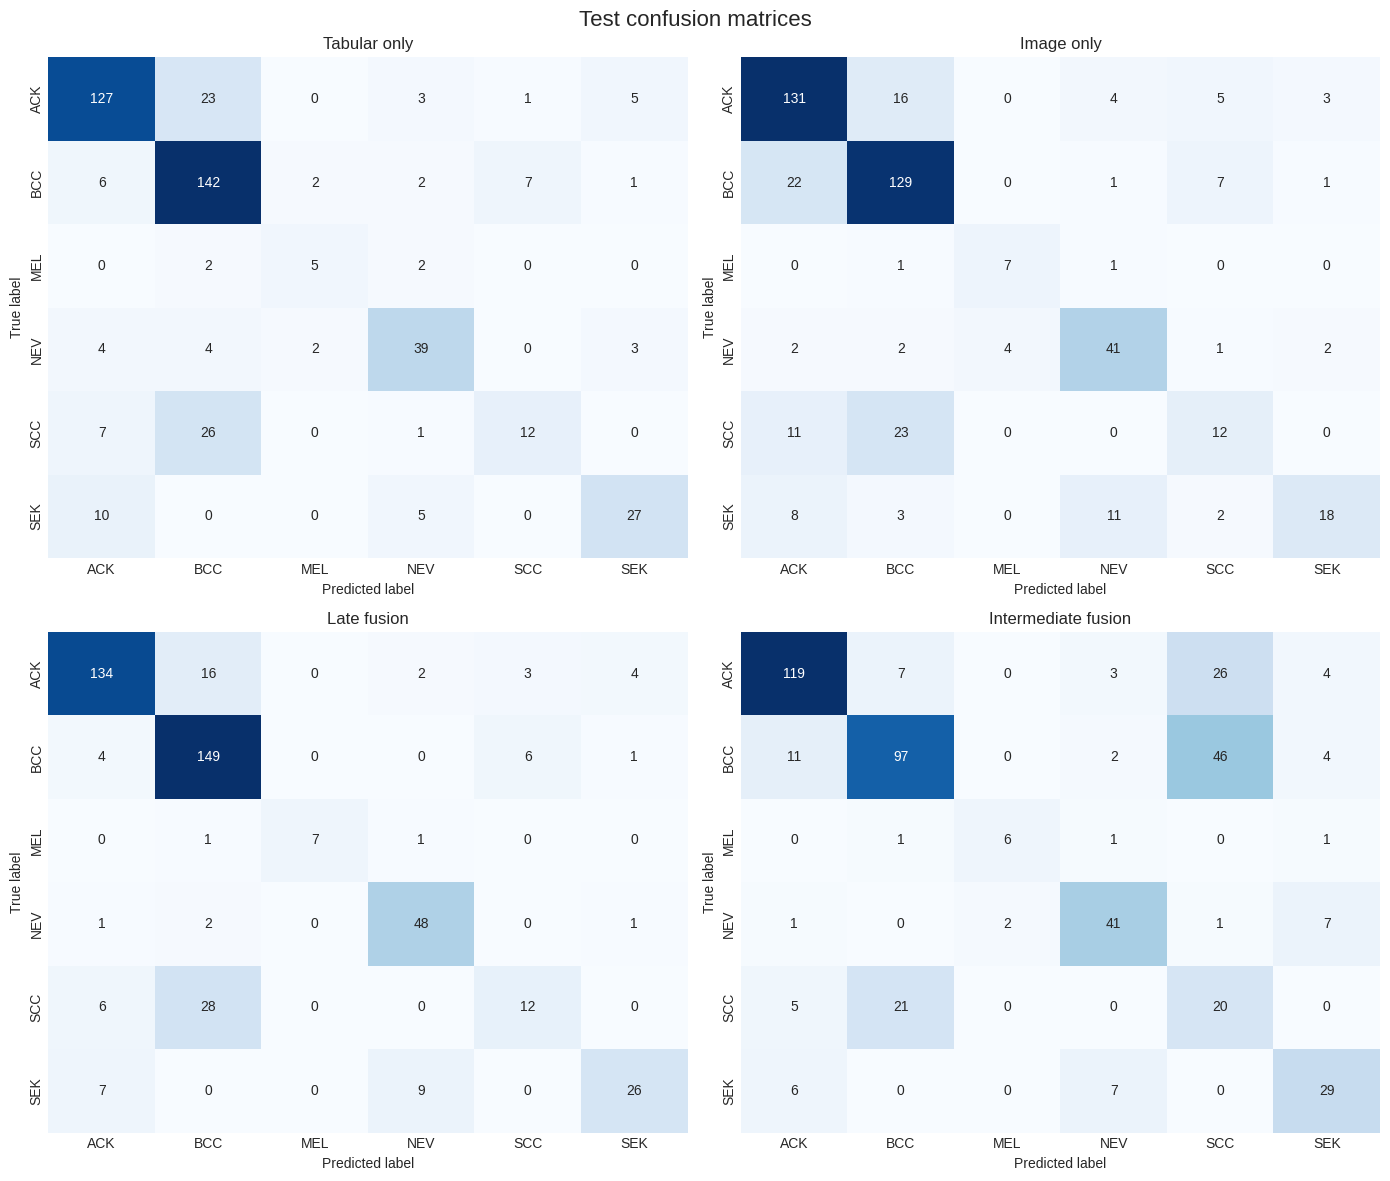

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (name, probs) in zip(axes.flat, test_probs.items()):
    cm = confusion_matrix(y_test, probs.argmax(1), labels=np.arange(NUM_CLASSES))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.suptitle("Test confusion matrices", fontsize=16)
plt.tight_layout()
plt.show()

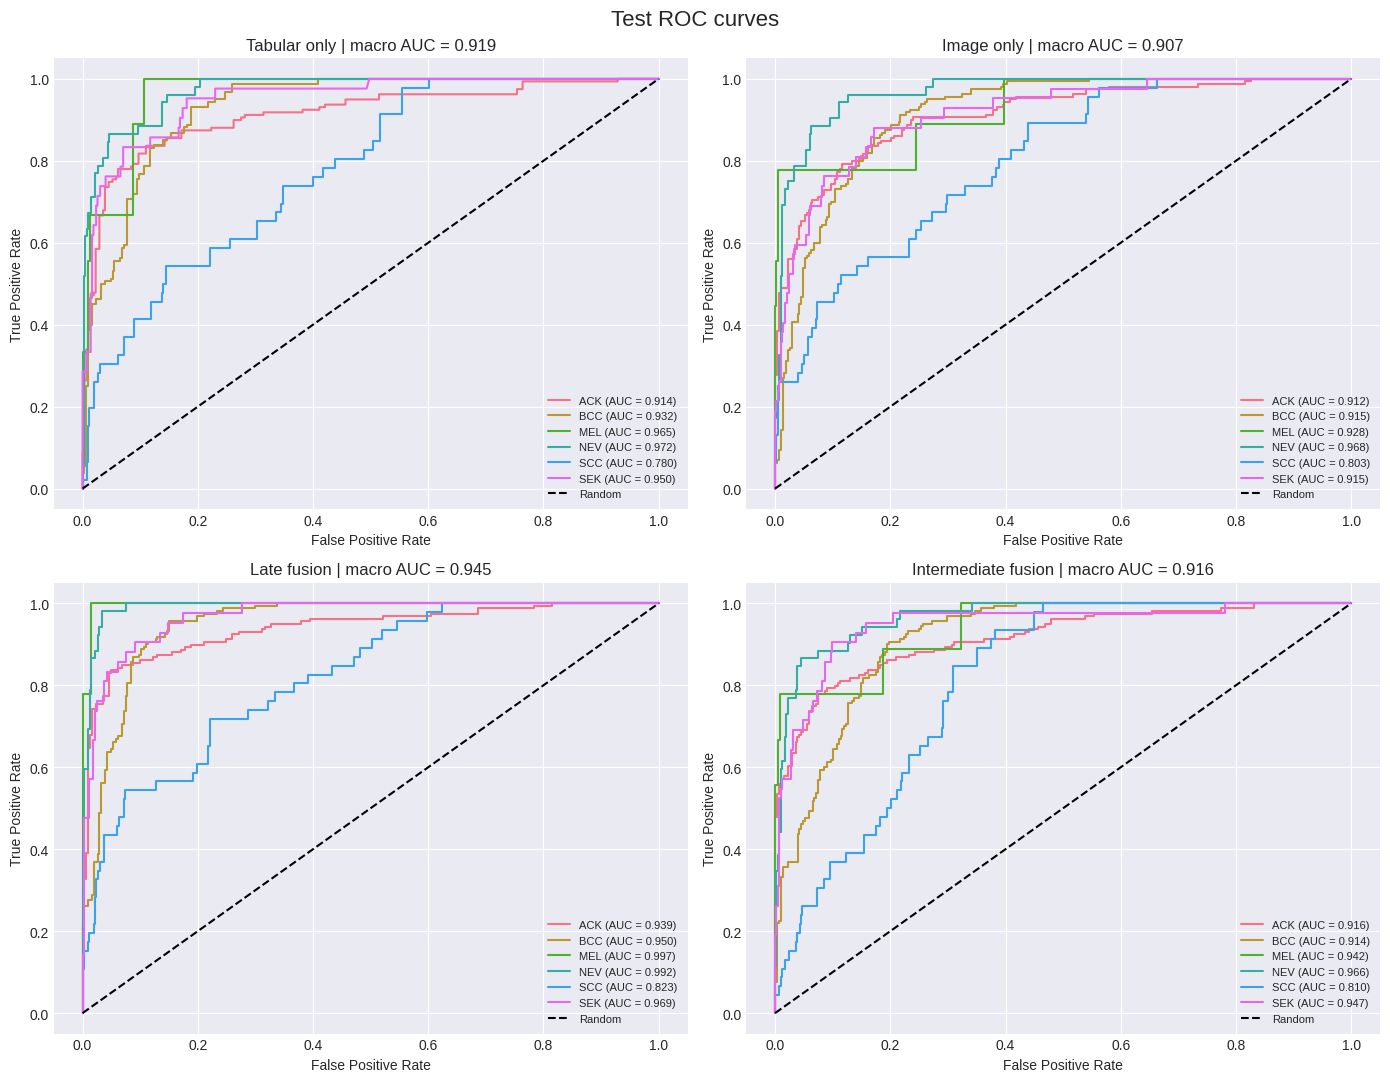

In [ ]:
# ROC curves (one-vs-rest)
y_test_binary = label_binarize(y_test, classes=np.arange(NUM_CLASSES))

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (name, probs) in zip(axes.flat, test_probs.items()):
    for i, cls in enumerate(CLASSES):
        if y_test_binary[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_test_binary[:, i], probs[:, i])
        ax.plot(fpr, tpr, label=f"{cls} (AUC = {auc(fpr, tpr):.3f})")

    ax.plot([0, 1], [0, 1], "k--", label="Random")
    ax.set_title(f"{name} | macro AUC = {test_results.loc[name, 'Macro ROC-AUC']:.3f}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right", fontsize=8)

plt.suptitle("Test ROC curves", fontsize=16)
plt.tight_layout()
plt.show()

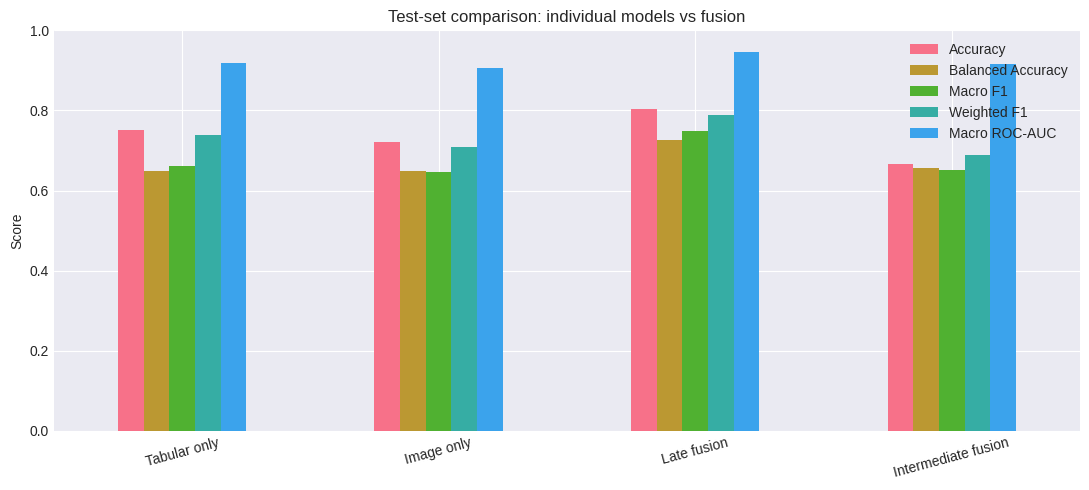

Saved results to: /content/drive/MyDrive/Colab Notebooks/ML/multimodal_artifacts/fusion/results


In [ ]:
# Overall metric comparison
test_results[["Accuracy", "Balanced Accuracy", "Macro F1", "Weighted F1", "Macro ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5))
plt.title("Test-set comparison: individual models vs fusion")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Save test predictions
predictions_df = pd.DataFrame({
    "img_id": df.iloc[test_idx]["img_id"].values,
    "patient_id": df.iloc[test_idx]["patient_id"].values,
    "true_label": [CLASSES[i] for i in y_test],
})
for name, probs in test_probs.items():
    predictions_df[f"pred_{name}"] = [CLASSES[i] for i in probs.argmax(1)]
    for i, cls in enumerate(CLASSES):
        predictions_df[f"prob_{name}_{cls}"] = probs[:, i]

predictions_df.to_csv(RESULT_DIR / "final_test_predictions.csv", index=False)
print("Saved results to:", RESULT_DIR)

## 13. Is the Difference Real? Patient-Level Bootstrap

The test fold is small (some classes, e.g. MEL, have only a handful of images), so a difference of a few points in macro F1 can be due to chance. The test patients are resampled with replacement (1,000 times) and the macro-F1 difference between two models is recomputed each time. If the 95% interval excludes 0, the difference is unlikely to be pure chance.

In [ ]:
test_patients = df.iloc[test_idx]["patient_id"].to_numpy()
unique_patients = np.unique(test_patients)
patient_rows = {p: np.where(test_patients == p)[0] for p in unique_patients}
test_pred = {name: probs.argmax(1) for name, probs in test_probs.items()}

N_BOOT = 100 if QUICK_TEST else 1000


def bootstrap_macro_f1_difference(pred_a, pred_b, n_boot=N_BOOT, seed=SEED):
    """Macro F1 of model A minus model B, resampling patients (not images)."""
    rng = np.random.default_rng(seed)
    differences = []
    for _ in range(n_boot):
        sampled = rng.choice(unique_patients, size=len(unique_patients), replace=True)
        rows = np.concatenate([patient_rows[p] for p in sampled])
        f1_a = f1_score(y_test[rows], pred_a[rows], average="macro", zero_division=0)
        f1_b = f1_score(y_test[rows], pred_b[rows], average="macro", zero_division=0)
        differences.append(f1_a - f1_b)

    differences = np.array(differences)
    low, high = np.percentile(differences, [2.5, 97.5])
    return differences.mean(), low, high, (differences > 0).mean()


comparisons = [
    ("Late fusion", "Image only"),
    ("Late fusion", "Tabular only"),
    ("Intermediate fusion", "Image only"),
    ("Intermediate fusion", "Tabular only"),
]

rows = []
for fusion_name, single_name in comparisons:
    mean_diff, low, high, p_better = bootstrap_macro_f1_difference(test_pred[fusion_name], test_pred[single_name])
    rows.append({
        "Comparison": f"{fusion_name}  vs  {single_name}",
        "Mean macro-F1 difference": round(mean_diff, 4),
        "95% interval": f"[{low:.3f}, {high:.3f}]",
        "Fusion better in (% of resamples)": round(100 * p_better, 1),
        "Interval excludes 0": bool(low > 0 or high < 0),
    })

display(pd.DataFrame(rows))

,Comparison,Mean macro-F1 difference,95% interval,Fusion better in (% of resamples),Interval excludes 0
0,Late fusion vs Image only,0.1058,"[0.046, 0.172]",99.9,True
1,Late fusion vs Tabular only,0.0915,"[-0.013, 0.205]",95.0,False
2,Intermediate fusion vs Image only,0.0066,"[-0.048, 0.070]",56.2,False
3,Intermediate fusion vs Tabular only,-0.0077,"[-0.125, 0.126]",42.7,False


## 14. Sanity Check: Structured Missing Clinical Data

The tabular notebook found that **804 records have the same 13 clinical fields missing, and all of them are ACK, NEV or SEK** (BCC, MEL and SCC always have clinical data). The `"Missing"` category can therefore act as a shortcut for the tabular and fusion models - partly a data-collection artefact rather than clinical information.

To check how much this matters, the test results are split into records **with** and **without** clinical data.

In [ ]:
# Check whether all clinical features are available
has_clinical = (
    df.iloc[test_idx][all_tabular]
    .notna()
    .all(axis=1)
    .to_numpy()
)

print(
    f"Complete clinical records: {has_clinical.sum()} | "
    f"Incomplete clinical records: {(~has_clinical).sum()}"
)


def subset_scores(mask):
    scores = {}
    for name, pred in test_pred.items():
        present = np.unique(y_test[mask])          # macro F1 over the classes present in the subset
        scores[name] = {
            "Accuracy": accuracy_score(y_test[mask], pred[mask]),
            "Macro F1": f1_score(y_test[mask], pred[mask], labels=present, average="macro", zero_division=0),
        }
    return pd.DataFrame(scores).T.reindex(MODEL_ORDER)


print("\nTest records WITH clinical data (all classes present)")
display(subset_scores(has_clinical).round(4))

if (~has_clinical).sum() > 0:
    print("Test records WITHOUT clinical data (only ACK / NEV / SEK exist here)")
    display(subset_scores(~has_clinical).round(4))

Complete clinical records: 295 | Incomplete clinical records: 173

Test records WITH clinical data (all classes present)


,Accuracy,Macro F1
Tabular only,0.6915,0.5141
Image only,0.6814,0.5346
Late fusion,0.7559,0.6589
Intermediate fusion,0.5559,0.5253


Test records WITHOUT clinical data (only ACK / NEV / SEK exist here)


,Accuracy,Macro F1
Tabular only,0.8555,0.8255
Image only,0.7919,0.7606
Late fusion,0.8844,0.8496
Intermediate fusion,0.8555,0.8245


## 15. Summary

In [ ]:
best_single = test_results.loc[["Tabular only", "Image only"], "Macro F1"].idxmax()
print(f"Tabular model used: {best_tab_name} | late-fusion image weight: {best_w}")
if best_w in (0.0, 1.0):
    print("NOTE: the CV search put all the weight on one modality, so late fusion is identical to that single model.")
print(f"Best individual model on the test set (macro F1): {best_single} = {test_results.loc[best_single, 'Macro F1']:.4f}\n")

for fusion_name in ["Late fusion", "Intermediate fusion"]:
    test_gain = test_results.loc[fusion_name, "Macro F1"] - test_results.loc[best_single, "Macro F1"]
    cv_means = cv_all.groupby("Model")["Macro F1"].mean()
    cv_gain = cv_means[fusion_name] - cv_means[["Tabular only", "Image only"]].max()

    print(f"{fusion_name}:")
    print(f"   test macro F1 = {test_results.loc[fusion_name, 'Macro F1']:.4f}  ({test_gain:+.4f} vs best individual model)")
    print(f"   CV   macro F1 = {cv_means[fusion_name]:.4f}  ({cv_gain:+.4f} vs best individual model)")

print("\nHow to read this:")
print(" - Fusion is only convincing if it improves BOTH the cross-validation and the test results,")
print("   and the bootstrap interval in section 13 excludes 0.")
print(" - Check the per-class tables: gains on MEL / SCC matter more clinically than gains on ACK / BCC.")
print(" - Compare section 14: a gain that only appears on records with 'Missing' clinical data is a dataset artefact.")

Tabular model used: Logistic Regression | late-fusion image weight: 0.4
Best individual model on the test set (macro F1): Tabular only = 0.6614

Late fusion:
   test macro F1 = 0.7486  (+0.0872 vs best individual model)
   CV   macro F1 = 0.6938  (+0.0672 vs best individual model)
Intermediate fusion:
   test macro F1 = 0.6505  (-0.0109 vs best individual model)
   CV   macro F1 = 0.6498  (+0.0232 vs best individual model)

How to read this:
 - Fusion is only convincing if it improves BOTH the cross-validation and the test results,
   and the bootstrap interval in section 13 excludes 0.
 - Check the per-class tables: gains on MEL / SCC matter more clinically than gains on ACK / BCC.
 - Compare section 14: a gain that only appears on records with 'Missing' clinical data is a dataset artefact.


## 16. Notes and Limitations

- **Small test fold:** about 450 images (about 20% of the patients). MEL has only a handful of test images, so per-class scores - especially MEL and SCC - are very uncertain. Use the cross-validation results (4 folds) together with the test results.
- **Structured missing clinical data** (section 14) makes the tabular modality look stronger than it may be clinically.
- **Late-fusion weight** is tuned on the cross-validation predictions (one parameter), so the late-fusion CV score is very slightly optimistic; the test score is not affected.
- **Repeated lesions:** several images can belong to the same lesion and share identical clinical data. Splitting is done at patient level, so this does not leak between train and test.
- **Not clinically validated:** experimental coursework models only.